# Cleaning and preprocessing the application table (modelling plan, Phase 2)

This notebook turns the 29 BAF application columns into model inputs. **Everything for Phase 2 is here**: the
recipe, the code that learns its numbers, the code that applies it, and the checks (team decision 10 Oct 2026).
Later phases never import code from this notebook; they read the files it writes.

**The one rule.** Every number the recipe learns (category levels, medians, means, spreads) comes from accounts
opened in months **0–4** only. The same numbers are then applied unchanged to month 5 (calibration) and months 6–7
(test). The application table is a public model input, so cleaning the test accounts is allowed; no test labels
are read. Each dataset (v1_full, v1, variant_II, variant_IV) is fitted on its own months 0–4 (decision 10 Oct 2026).

The data has no true NaN, duplicates or broken keys (the simulator's 10 checks), so "cleaning" means BAF's
missing codes (it writes "unknown" as −1 or a negative amount) and turning columns into a form each model can use.
**Two outputs**, because the models want different things:

| mode | for | what it does |
|---|---|---|
| `linear` | logistic regression, autoencoder | missing code -> median + flag, log of skewed columns, one-hot categories, standardised |
| `tree` | LightGBM | missing code -> NaN + flag (LightGBM handles NaN itself), raw scale, categories as `category` dtype |

| § | What | Output |
|---|---|---|
| 1 | The recipe, one entry per column | the column table in the report is printed from it |
| 2 | Before: the table as it arrives | compared with the EDA report §1 |
| 3 | `fit`: learn the numbers from months 0–4 | |
| 4 | `transform`: apply them to any accounts | |
| 5 | Apply to months 0–7 and save | `<data>/features/accounts_linear.parquet`, `accounts_tree.parquet`, `preprocess_manifest.json`; `<report>/params.json` |
| 6 | After: the column table, what the missing flags say | figure |
| 7 | Checks (any failure stops the notebook) | |
| 8 | Write the report | `<report>/report.md` |

**How to run.** From the repo root, `PYTHONPATH=src python -m features preprocess` runs this notebook on
`data/v1_full` and saves the executed copy here; `--out data/v1 --report outputs/modelling/preprocess/v1_50k` runs it on
the 50k data, `--out data/variant_II` on a variant. Interactively, set `EDA_DATA` and `EDA_REPORT` before starting the
kernel (the same names as the EDA notebook; defaults `data/v1_full`, `outputs/modelling/preprocess`).

## 0. Setup

Paths, the training months, and the helpers shared with the EDA notebook (`log` writes to the report as well as the
screen). The DuckDB connection holds only the two public tables.

In [1]:
from __future__ import annotations

import json
import os
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib

if "ipykernel" not in sys.modules:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt

# Find the repo root (the folder that holds src/amldata), move there and put src/ on the path, so the notebook runs
# the same from VS Code / Jupyter ("Run All" starts in notebooks/) and from `python -m features ...` (starts at the root).
ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "amldata").is_dir():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("start this notebook from inside the aml-detection-system repo")
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import amldata
from amldata import labels
from features.manifest import _git, _sha256

warnings.filterwarnings("ignore", category=FutureWarning)

OUT = os.environ.get("EDA_DATA", amldata.DEFAULT_OUT)
RUN = os.path.basename(os.path.normpath(OUT))
REPORT = Path(os.environ.get("EDA_REPORT", "outputs/modelling/preprocess" + ("" if RUN == "v1_full" else f"/{RUN}")))
FEATURES = Path(OUT) / "features"
TRAIN = (0, 1, 2, 3, 4)                   # the recipe learns its numbers from these months only
SPLITS = {"months 0-4": (0, 1, 2, 3, 4), "month 5": (5,), "months 6-7": (6, 7)}
KEYS = ["account_id", "open_month"]      # carried through so later phases can join; never features
NOT_FEATURES = ["account_id", "open_month", "open_day"]
MODES = ("linear", "tree")
RECIPE_VERSION = 1                        # bump when the recipe below changes

REPORT.mkdir(parents=True, exist_ok=True)
FEATURES.mkdir(parents=True, exist_ok=True)
_lines: list[str] = []
T0 = time.time()


def log(msg: str = "") -> None:
    print(msg)
    _lines.append(str(msg))


def header(title: str) -> None:
    log("\n" + "=" * 78 + f"\n{title}\n" + "=" * 78)


def table(df: pd.DataFrame, floatfmt: str = ".4f", index: bool = True) -> None:
    log(df.to_markdown(index=index, floatfmt=floatfmt))
    log("")


def savefig(fig, name: str) -> None:
    """Save the figure for the report and, inside a notebook kernel, show it inline too."""
    fig.tight_layout()
    fig.savefig(REPORT / f"{name}.png", dpi=120)
    if "ipykernel" in sys.modules:
        from IPython.display import display
        display(fig)
    plt.close(fig)
    print(f"  [fig] {REPORT / name}.png")


con = amldata.public(OUT)                               # views: accounts, transactions. Nothing else.
log(f"DATA   : {OUT}\nREPORT : {REPORT}\nfitted on months {TRAIN}; applied to months 0-7")
log(f"pandas {pd.__version__} | python {sys.version.split()[0]}")

DATA   : data/sensitivity/seed__44
REPORT : outputs/modelling/preprocess/seed__44
fitted on months (0, 1, 2, 3, 4); applied to months 0-7
pandas 3.0.6 | python 3.12.15


## 1. Application EDA

One entry per application column. `kind` decides what happens to it:

- **continuous**: a number. `linear` mode logs it if `log` is set, fills missing values with the months 0–4 median,
  then standardises it (mean 0, spread 1). `tree` mode keeps the raw value.
- **binned**: BAF already rounded it into a few bands (`income` deciles, `customer_age` decades, `proposed_credit_limit`).
  Kept as a number and treated like a continuous column.
- **binary**: 0/1. Kept as is in both modes.
- **categorical**: a code such as `housing_status = BA`. `linear` mode makes one 0/1 column per level seen in months 0–4
  (a level never seen there gives all zeros); `tree` mode keeps one `category` column (an unseen level becomes NaN).

`missing` means BAF writes "unknown" as a negative value: it becomes NaN plus a `<column>_missing` flag (1 = was
unknown), in both modes. `clip` is a fixed rule: `velocity_6h` should never be negative, and the few negative rows
(none in months 0–4) are set to 0. `credit_risk_score` runs negative as a real score, so it is left alone.
The reasons come from the EDA report §1 (`outputs/modelling/eda/report.md`). `open_month`, `open_day` and
`account_id` are never features.

**`log` is used only where it makes a column less lopsided** (skew closer to 0). Skew measures how far the
values lean to one side: positive = a long tail of big values, negative = a long tail of small values; the size, not the
sign, is what hurts a linear model, because a few extreme accounts then get a big say in its weight. The log squeezes
big values together and spreads small ones apart, so it helps a long right tail but over-corrects a column that is
already nearly balanced. **Change 10 Oct 2026 (team decision):** the plan logged 9 columns; on v1_full months 0–4 the
log helped 5 (`days_since_request` 8.86 -> 3.48, `prev_address_months_count` 2.34 -> 0.39, `session_length_in_minutes`
3.23 -> 0.55, `bank_branch_count_8w` 2.68 -> 0.87, `zip_count_4w` 1.34 -> −0.24) and made 4 worse, so they are no
longer logged: `intended_balcon_amount` 1.34 -> −1.15, `velocity_6h` 0.34 -> −1.20, `velocity_24h` 0.32 -> −0.34,
`velocity_4w` 0.11 -> −0.45 (skew with missing codes removed). The same rule then added one column the plan had not
logged: `current_address_months_count` 1.41 -> −0.54. Not logged although the log would lower the skew:
`proposed_credit_limit` (BAF bands, kept as numbers like the other binned columns) and `device_distinct_emails_8w`
(only 0, 1 or 2). Section 6 shows the skew with and without the log for
every continuous column, and section 7 checks that each logged column really is less lopsided after the log.
`tree` mode never logs: trees use only the order of the values, which a log does not change.

In [2]:
header("1. THE RECIPE (one entry per application column)")

C, B, BIN, CAT = "continuous", "binned", "binary", "categorical"


def rule(kind: str, missing: bool = False, clip: bool = False, log: bool = False, note: str = "") -> dict:
    return {"kind": kind, "missing": missing, "clip": clip, "log": log, "note": note}


RECIPE = {
    "income":                           rule(B, note="BAF deciles 0.1-0.9"),
    "name_email_similarity":            rule(C, note="0-1 score"),
    "prev_address_months_count":        rule(C, missing=True, log=True, note="-1 = unknown; skewed"),
    "current_address_months_count":     rule(C, missing=True, log=True, note="-1 = unknown; log added: skew 1.4 -> -0.5 (changed 10 Oct 2026)"),
    "customer_age":                     rule(B, note="BAF decades 10-90"),
    "days_since_request":               rule(C, log=True, note="very skewed"),
    "intended_balcon_amount":           rule(C, missing=True, note="negative = no amount given; no log: it turns skew 1.3 into -1.2 (changed 10 Oct 2026)"),
    "payment_type":                     rule(CAT),
    "zip_count_4w":                     rule(C, log=True, note="skewed count"),
    "velocity_6h":                      rule(C, clip=True, note="never negative in months 0-4; clip is a fixed rule; no log: barely skewed (changed 10 Oct 2026)"),
    "velocity_24h":                     rule(C, note="no log: barely skewed (changed 10 Oct 2026)"),
    "velocity_4w":                      rule(C, note="no log: barely skewed (changed 10 Oct 2026)"),
    "bank_branch_count_8w":             rule(C, log=True, note="skewed count"),
    "date_of_birth_distinct_emails_4w": rule(C, note="count"),
    "employment_status":                rule(CAT),
    "credit_risk_score":                rule(C, note="negative values are real scores: keep"),
    "email_is_free":                    rule(BIN),
    "housing_status":                   rule(CAT),
    "phone_home_valid":                 rule(BIN),
    "phone_mobile_valid":               rule(BIN),
    "bank_months_count":                rule(C, missing=True, note="-1 = unknown"),
    "has_other_cards":                  rule(BIN),
    "proposed_credit_limit":            rule(B, note="12 BAF bands"),
    "foreign_request":                  rule(BIN),
    "source":                           rule(CAT),
    "session_length_in_minutes":        rule(C, missing=True, log=True, note="-1 = unknown; skewed"),
    "device_os":                        rule(CAT),
    "keep_alive_session":               rule(BIN),
    "device_distinct_emails_8w":        rule(C, missing=True, note="-1 = unknown; count 0-2"),
}
MISSING_COLS = [c for c, r in RECIPE.items() if r["missing"]]
CAT_COLS = [c for c, r in RECIPE.items() if r["kind"] == CAT]
BIN_COLS = [c for c, r in RECIPE.items() if r["kind"] == BIN]
LOG_COLS = [c for c, r in RECIPE.items() if r["log"]]

recipe_df = pd.DataFrame(RECIPE).T
recipe_df.index.name = "column"
table(recipe_df, index=True)
log(f"{len(RECIPE)} columns: " + ", ".join(f"{k} {v}" for k, v in recipe_df["kind"].value_counts().items())
    + f"; missing code in {len(MISSING_COLS)}, log1p (linear only) on {len(LOG_COLS)}")


1. THE RECIPE (one entry per application column)
| column                           | kind        | missing   | clip   | log   | note                                                                                            |
|:---------------------------------|:------------|:----------|:-------|:------|:------------------------------------------------------------------------------------------------|
| income                           | binned      | False     | False  | False | BAF deciles 0.1-0.9                                                                             |
| name_email_similarity            | continuous  | False     | False  | False | 0-1 score                                                                                       |
| prev_address_months_count        | continuous  | True      | False  | True  | -1 = unknown; skewed                                                                            |
| current_address_months_count     | continuous  | True     

## 2. Before: the table as it arrives

All accounts (months 0–7) are read once; only months 0–4 are described. The share of BAF missing codes per column
should equal the EDA report §1 exactly when this runs on the same data. The cell checks that against the saved
EDA report (v1_full and the 50k copy; skipped for datasets with no EDA report). The share by split is shown too,
since the recipe has to cope with whatever months 5–7 contain.

In [3]:
header("2. BEFORE: THE APPLICATION TABLE AS IT ARRIVES")

acc = con.execute("SELECT * FROM accounts").df()
baf = [c for c in acc.columns if c not in NOT_FEATURES]
assert sorted(baf) == sorted(RECIPE), f"recipe and data disagree: {set(baf) ^ set(RECIPE)}"
train_raw = acc[acc["open_month"].isin(TRAIN)]
log(f"accounts: {len(acc):,} in months 0-7; {len(train_raw):,} in months 0-4 (the recipe learns from these only)")
log(f"true NaN in the application columns: {int(acc[baf].isna().sum().sum())} (BAF writes unknown as a negative code)")

log("\nshare of rows with a negative value, by split (BAF missing codes; credit_risk_score is a real score):")
codes = pd.DataFrame({name: {c: float((acc.loc[acc["open_month"].isin(m), c] < 0).mean())
                             for c in MISSING_COLS + ["credit_risk_score", "velocity_6h"]}
                      for name, m in SPLITS.items()})
codes["min (months 0-4)"] = [float(train_raw[c].min()) for c in codes.index]
codes["negative rows, all months"] = [int((acc[c] < 0).sum()) for c in codes.index]
codes["recipe"] = ["NaN + flag" if c in MISSING_COLS else "keep (real score)" if c == "credit_risk_score"
                   else "clip at 0" for c in codes.index]
table(codes.sort_values("months 0-4", ascending=False))

EDA_REPORTS = {"v1_full": Path("outputs/modelling/eda/report.md"), "v1": Path("outputs/modelling/eda/v1_50k/report.md")}
eda = EDA_REPORTS.get(RUN)
if eda is not None and eda.exists():
    text = eda.read_text(encoding="utf-8").split("categorical levels:")[0]
    eda_rows = {}
    for line in text.splitlines():
        parts = [p.strip() for p in line.strip().strip("|").split("|")]
        if len(parts) == 4 and parts[0] in RECIPE:
            eda_rows[parts[0]] = (float(parts[1]), float(parts[2]))
    diffs = {c: (eda_rows[c], (round(codes.loc[c, "months 0-4"], 4), round(codes.loc[c, "min (months 0-4)"], 4)))
             for c in eda_rows
             if abs(eda_rows[c][0] - codes.loc[c, "months 0-4"]) > 5e-5 or abs(eda_rows[c][1] - codes.loc[c, "min (months 0-4)"]) > 5e-5}
    assert len(eda_rows) == 8 and not diffs, f"differs from {eda}: {diffs}"
    log(f"matches the EDA report §1 ({eda}): all {len(eda_rows)} rows, share and minimum")
else:
    log(f"no EDA report for {RUN}: comparison with EDA §1 skipped")

log("\ncategorical levels in months 0-4, and rows in months 5-7 with a level not seen there:")
later = acc[~acc["open_month"].isin(TRAIN)]
table(pd.DataFrame({"levels": [train_raw[c].nunique() for c in CAT_COLS],
                    "values": [", ".join(sorted(train_raw[c].astype(str).unique())) for c in CAT_COLS],
                    "unseen rows, months 5-7": [int((~later[c].isin(train_raw[c].unique())).sum()) for c in CAT_COLS]},
                   index=CAT_COLS))


2. BEFORE: THE APPLICATION TABLE AS IT ARRIVES
accounts: 244,000 in months 0-7; 164,829 in months 0-4 (the recipe learns from these only)
true NaN in the application columns: 0 (BAF writes unknown as a negative code)

share of rows with a negative value, by split (BAF missing codes; credit_risk_score is a real score):
|                              |   months 0-4 |   month 5 |   months 6-7 |   min (months 0-4) |   negative rows, all months | recipe            |
|:-----------------------------|-------------:|----------:|-------------:|-------------------:|----------------------------:|:------------------|
| intended_balcon_amount       |       0.7299 |    0.7713 |       0.7661 |           -13.2028 |                      181120 | NaN + flag        |
| prev_address_months_count    |       0.6968 |    0.8248 |       0.7067 |            -1.0000 |                      174272 | NaN + flag        |
| bank_months_count            |       0.2556 |    0.2268 |       0.2659 |            -1.0000 |

## 3. `fit`: learn the numbers from months 0–4

`fit` takes the whole accounts table and picks out months 0–4 itself, so it cannot see other months by mistake
(section 7 checks that changing months 5–7 leaves its result unchanged). It learns:

- the levels of each categorical column,
- for every continuous or binned column, after the missing-code step, the clip and the log: the **median** (used to
  fill missing values in `linear` mode), then the **mean** and **spread** (standard deviation) used to standardise.

The steps that need no learned numbers (missing code -> NaN + flag, clip, log) live in `_row_steps`, which both
`fit` and `transform` call, so the two cannot drift apart.

In [4]:
def _row_steps(x: pd.Series, r: dict, mode: str) -> tuple[pd.Series, pd.Series | None]:
    """Steps that need no learned numbers, row by row: missing code -> NaN (+ flag), clip at 0, log1p (linear only)."""
    x = x.astype("float64")
    flag = None
    if r["missing"]:
        flag = (x < 0).astype("int8")
        x = x.where(x >= 0)
    if r["clip"]:
        x = x.clip(lower=0)
    if mode == "linear" and r["log"]:
        x = np.log1p(x)
    return x, flag


def fit(accounts: pd.DataFrame) -> dict:
    """Learn the recipe's numbers from accounts opened in months 0-4; rows of other months are ignored."""
    train = accounts[accounts["open_month"].isin(TRAIN)]
    params = {"fitted_on": {"months": list(TRAIN), "n_accounts": int(len(train))},
              "levels": {}, "median": {}, "mean": {}, "std": {}}
    for c, r in RECIPE.items():
        if r["kind"] == CAT:
            params["levels"][c] = sorted(train[c].astype(str).unique().tolist())
        elif r["kind"] in (C, B):
            x, _ = _row_steps(train[c], r, "linear")
            med = float(x.median())
            x = x.fillna(med)
            sd = float(x.std(ddof=0))
            params["median"][c] = med
            params["mean"][c] = float(x.mean())
            params["std"][c] = sd if sd > 0 else 1.0
    return params

## 4. `transform`: apply the numbers to any accounts

A pure function of one account's row and the fitted numbers: it never looks at other rows, so cleaning month 6 on
its own gives the same result as cleaning it with everything else (checked in section 7). The output keeps
`account_id` and `open_month` first as keys, then the features in recipe order. One-hot columns are named
`<column>_<level>`, missing flags `<column>_missing`.

In [5]:
def transform(accounts: pd.DataFrame, params: dict, mode: str) -> pd.DataFrame:
    """Clean `accounts` with fitted `params`. mode 'linear' (logistic regression, autoencoder) or 'tree' (LightGBM)."""
    if mode not in MODES:
        raise ValueError(f"mode must be one of {MODES}")
    cols = {k: accounts[k] for k in KEYS}
    for c, r in RECIPE.items():
        if r["kind"] == CAT:
            x = accounts[c].astype(str)
            levels = params["levels"][c]
            if mode == "tree":
                cols[c] = pd.Series(pd.Categorical(x, categories=levels), index=accounts.index)
            else:
                for lv in levels:
                    cols[f"{c}_{lv}"] = (x == lv).astype("int8")
        elif r["kind"] == BIN:
            cols[c] = accounts[c].astype("int8")
        else:
            x, flag = _row_steps(accounts[c], r, mode)
            if mode == "linear":
                x = (x.fillna(params["median"][c]) - params["mean"][c]) / params["std"][c]
            cols[c] = x
            if flag is not None:
                cols[f"{c}_missing"] = flag
    return pd.DataFrame(cols, index=accounts.index)

## 5. Apply to months 0–7 and save

Fit once on months 0–4, clean every account, and write:

- `<data>/features/accounts_linear.parquet` and `accounts_tree.parquet`: one row per account (months 0–7), keys first.
- `<data>/features/preprocess_manifest.json`: the recipe, the fitted numbers, the output columns per mode, a
  fingerprint (sha256) of the data run's `run_manifest.json`, the code commit and package versions. Later phases
  refuse files whose fingerprint does not match the data they are given.
- `<report>/params.json`: the same recipe and fitted numbers, committed with the report (no commit hash, so it only
  changes when the numbers do).

Plain JSON instead of a pickled object: readable, shows up in a git diff, and loads without this notebook's code.

In [6]:
header("5. APPLY TO MONTHS 0-7 AND SAVE")

params = fit(acc)
out_frames = {m: transform(acc, params, m) for m in MODES}
for m, f in out_frames.items():
    f.to_parquet(FEATURES / f"accounts_{m}.parquet", index=False)
    n_feat = f.shape[1] - len(KEYS)
    log(f"{m:6s}: {len(f):,} accounts x {n_feat} features -> {FEATURES / f'accounts_{m}.parquet'}")

params_doc = {
    "recipe_version": RECIPE_VERSION,
    "notebook": "notebooks/02_preprocess.ipynb",
    "data_folder": OUT,
    "run_manifest_sha256": _sha256(os.path.join(OUT, "run_manifest.json")),
    "keys": KEYS,
    "recipe": RECIPE,
    "params": params,
    "columns": {m: [c for c in f.columns if c not in KEYS] for m, f in out_frames.items()},
}
dirty = _git("status", "--porcelain", "--untracked-files=no")
manifest = {**params_doc,
            "files": {m: f"accounts_{m}.parquet" for m in MODES},
            "git_commit": _git("rev-parse", "HEAD"),
            "git_uncommitted_changes": bool(dirty) if dirty is not None else None,
            "python": sys.version.split()[0],
            "packages": {"numpy": np.__version__, "pandas": pd.__version__}}
(FEATURES / "preprocess_manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
(REPORT / "params.json").write_text(json.dumps(params_doc, indent=2), encoding="utf-8")
log(f"manifest -> {FEATURES / 'preprocess_manifest.json'}\nparams   -> {REPORT / 'params.json'}")
log(f"fitted on {params['fitted_on']['n_accounts']:,} accounts in months {params['fitted_on']['months']}")


5. APPLY TO MONTHS 0-7 AND SAVE


linear: 244,000 accounts x 56 features -> data/sensitivity/seed__44/features/accounts_linear.parquet
tree  : 244,000 accounts x 35 features -> data/sensitivity/seed__44/features/accounts_tree.parquet
manifest -> data/sensitivity/seed__44/features/preprocess_manifest.json
params   -> outputs/modelling/preprocess/seed__44/params.json
fitted on 164,829 accounts in months [0, 1, 2, 3, 4]


## 6. After: the column table, and what the missing flags say

The column-by-column table for the report: what each mode does to each column, the share of missing codes in months
0–4, the median used to fill them, and the skew (lopsidedness): before (missing codes removed), what it would be after
`log1p` (shown for every non-negative continuous column, logged or not, as the evidence for section 1's choice), and in
the final `linear` output. A skew far from 0 on either side means a few extreme accounts dominate, which hurts linear
models. The final `linear` skew also includes the filled-in medians, so for columns with many missing codes it differs
from the "if log1p" figure.

Then the missing flags, by group (normal accounts, fake accounts, real-customer mules) on months 0–4 labels. A flag
whose rate differs between groups carries signal, which is why the flags are kept as features in both modes.


6. AFTER: THE COLUMN TABLE (months 0-4) AND THE MISSING FLAGS
| column                           | kind        | linear                                   | tree               |   missing share |   fill median |   skew before |   skew if log1p |   skew after (linear) |
|:---------------------------------|:------------|:-----------------------------------------|:-------------------|----------------:|--------------:|--------------:|----------------:|----------------------:|
| income                           | binned      | standardise                              | raw                |         nan     |       nan     |        -0.288 |          -0.448 |                -0.288 |
| name_email_similarity            | continuous  | standardise                              | raw                |         nan     |       nan     |        -0.028 |          -0.246 |                -0.028 |
| prev_address_months_count        | continuous  | NaN -> median + flag, log1p, standardise | NaN kept + flag

share of accounts with each missing flag, by group (months 0-4; group sizes normal 164,375, fake 328, real mule 126):
|                                      |   normal |   fake |   real mule |   accounts flagged |
|:-------------------------------------|---------:|-------:|------------:|-------------------:|
| prev_address_months_count_missing    |   0.6964 | 0.9085 |      0.6587 |            114,847 |
| current_address_months_count_missing |   0.0041 | 0.0000 |      0.0079 |                674 |
| intended_balcon_amount_missing       |   0.7296 | 0.8811 |      0.7381 |            120,312 |
| bank_months_count_missing            |   0.2554 | 0.3963 |      0.2063 |             42,134 |
| session_length_in_minutes_missing    |   0.0020 | 0.0000 |      0.0000 |                335 |
| device_distinct_emails_8w_missing    |   0.0005 | 0.0000 |      0.0000 |                 78 |

  -> a flag whose rate differs between groups carries signal; the flags are kept as features in both modes.


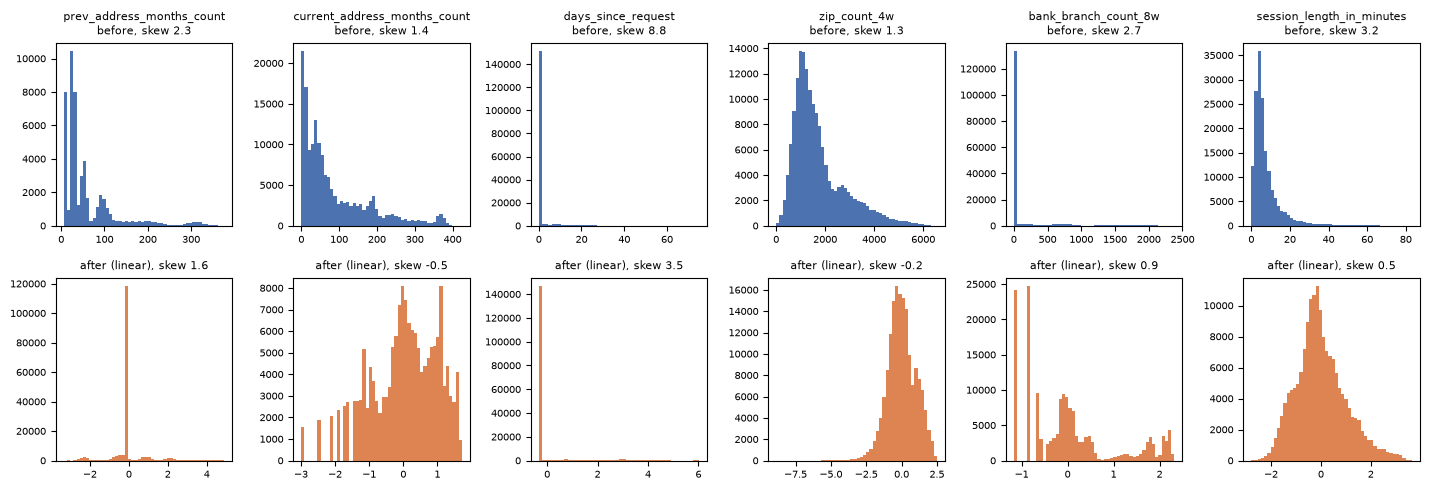

  [fig] outputs/modelling/preprocess/seed__44/01_log_columns_before_after.png


In [7]:
header("6. AFTER: THE COLUMN TABLE (months 0-4) AND THE MISSING FLAGS")

tr_lin = out_frames["linear"].loc[train_raw.index]
tr_tree = out_frames["tree"].loc[train_raw.index]
rows = []
for c, r in RECIPE.items():
    row = {"column": c, "kind": r["kind"]}
    if r["kind"] == CAT:
        k = len(params["levels"][c])
        row.update({"linear": f"one-hot, {k} columns", "tree": f"category, {k} levels"})
    elif r["kind"] == BIN:
        row.update({"linear": "0/1 as is", "tree": "0/1 as is"})
    else:
        steps = (["clip at 0"] if r["clip"] else []) + (["log1p"] if r["log"] else [])
        lin_steps = (["NaN -> median + flag"] if r["missing"] else []) + steps + ["standardise"]
        row.update({"linear": ", ".join(lin_steps),
                    "tree": ", ".join((["NaN kept + flag"] if r["missing"] else []) + (["clip at 0"] if r["clip"] else []))
                            or "raw",
                    "missing share": float(tr_tree[c].isna().mean()) if r["missing"] else np.nan,
                    "fill median": params["median"][c] if r["missing"] else np.nan,
                    "skew before": float(tr_tree[c].skew()),
                    "skew if log1p": float(np.log1p(tr_tree[c]).skew()) if tr_tree[c].min() >= 0 else np.nan,
                    "skew after (linear)": float(tr_lin[c].skew())})
    rows.append(row)
col_table = pd.DataFrame(rows).set_index("column")
table(col_table, floatfmt=".3f")
for m, cols in params_doc["columns"].items():
    log(f"{m} mode: {len(cols)} feature columns")
log("")

lab = labels(OUT, months=TRAIN, profile=True)
flag_cols = [f"{c}_missing" for c in MISSING_COLS]
fl = tr_lin[["account_id"] + flag_cols].merge(lab, on="account_id", how="left", validate="1:1")
fl["group"] = np.where(fl["is_launderer"] == 0, "normal", np.where(fl["profile"] == "fake", "fake", "real mule"))
rates = fl.groupby("group")[flag_cols].mean().T
rates["accounts flagged"] = [f"{int(n):,}" for n in fl[flag_cols].sum()]
log("share of accounts with each missing flag, by group (months 0-4; group sizes "
    + ", ".join(f"{g} {n:,}" for g, n in fl["group"].value_counts().items()) + "):")
table(rates[["normal", "fake", "real mule", "accounts flagged"]], floatfmt=".4f")
log("  -> a flag whose rate differs between groups carries signal; the flags are kept as features in both modes.")

fig, axes = plt.subplots(2, len(LOG_COLS), figsize=(2.4 * len(LOG_COLS), 5))
for j, c in enumerate(LOG_COLS):
    axes[0, j].hist(tr_tree[c].dropna(), bins=50, color="#4c72b0")
    axes[0, j].set_title(f"{c}\nbefore, skew {tr_tree[c].skew():.1f}", fontsize=8)
    axes[1, j].hist(tr_lin[c], bins=50, color="#dd8452")
    axes[1, j].set_title(f"after (linear), skew {tr_lin[c].skew():.1f}", fontsize=8)
    for ax in axes[:, j]:
        ax.tick_params(labelsize=7)
savefig(fig, "01_log_columns_before_after")

## 7. Checks

Each check is an `assert`: if one fails, the notebook stops and `python -m features preprocess` (and its pytest)
fails. They cover the promises the later phases rely on: no NaN in `linear` mode, NaN only where BAF wrote a missing
code in `tree` mode, identical columns for every split, fitted numbers that depend on months 0–4 alone, and saved
files and JSON that reproduce the cleaned tables exactly.

In [8]:
header("7. CHECKS (any failure stops the notebook)")


def check(name: str, cond: bool, detail: str = "") -> None:
    assert cond, f"FAILED: {name} {detail}"
    log(f"  ok  {name}" + (f" ({detail})" if detail else ""))


lin, tree = out_frames["linear"], out_frames["tree"]
feat = lambda f: [c for c in f.columns if c not in KEYS]

check("every account kept once, in input order, keys first",
      all(list(f.columns[:2]) == KEYS and (f["account_id"].to_numpy() == acc["account_id"].to_numpy()).all()
          for f in out_frames.values()))
check("open_day is never an output; account_id and open_month only as keys",
      all("open_day" not in f.columns and not set(NOT_FEATURES) & set(feat(f)) for f in out_frames.values()))
check("linear mode has no NaN", not lin[feat(lin)].isna().any().any())
check("tree mode: NaN exactly where BAF wrote a missing code",
      all((tree[c].isna() == (acc[c] < 0)).all() for c in MISSING_COLS))
unseen = int(sum(tree[c].isna().sum() for c in CAT_COLS))
check("tree mode: no NaN in any other numeric column",
      not tree[[c for c in feat(tree) if c not in MISSING_COLS + CAT_COLS]].isna().any().any(),
      f"categorical NaN from levels unseen in months 0-4: {unseen}")
check("missing flags = negative code, identical in both modes",
      all((lin[f"{c}_missing"] == (acc[c] < 0)).all() and (tree[f"{c}_missing"] == lin[f"{c}_missing"]).all()
          for c in MISSING_COLS))
check("velocity_6h is never negative after cleaning (tree mode)", bool((tree["velocity_6h"] >= 0).all()),
      f"{int((acc['velocity_6h'] < 0).sum())} rows clipped, all in months "
      f"{sorted(acc.loc[acc['velocity_6h'] < 0, 'open_month'].unique().tolist())}")
tr_raw_tree = tree[tree["open_month"].isin(TRAIN)]
worse = {c: (round(float(tr_raw_tree[c].skew()), 2), round(float(np.log1p(tr_raw_tree[c]).skew()), 2)) for c in LOG_COLS
         if abs(np.log1p(tr_raw_tree[c]).skew()) >= abs(tr_raw_tree[c].skew())}
check("every logged column is less lopsided after log1p on months 0-4 (decision 10 Oct 2026)", not worse,
      f"{len(LOG_COLS)} logged" + (f"; worse: {worse}" if worse else ""))
check("binary columns hold only 0 and 1", all(set(acc[c].unique()) <= {0, 1} for c in BIN_COLS))
check("linear: each categorical has at most one level set per account",
      all(lin[[f"{c}_{lv}" for lv in params["levels"][c]]].sum(axis=1).le(1).all() for c in CAT_COLS))

tr = lin[lin["open_month"].isin(TRAIN)]
std_cols = list(params["mean"])
worst_mean = float(tr[std_cols].mean().abs().max())
worst_sd = float((tr[std_cols].std(ddof=0) - 1).abs().max())
check("linear: standardised columns have mean 0 and spread 1 on months 0-4", worst_mean < 1e-9 and worst_sd < 1e-9,
      f"worst |mean| {worst_mean:.1e}, worst |sd - 1| {worst_sd:.1e}")

check("fit is repeatable", fit(acc) == params)
shaken = acc.copy()
later_rows = ~shaken["open_month"].isin(TRAIN)
num_cols = [c for c in RECIPE if c not in CAT_COLS]
shaken.loc[later_rows, num_cols] = shaken.loc[later_rows, num_cols] * 10 + 7
for c in CAT_COLS:
    shaken.loc[later_rows, c] = "ZZ"
check("changing every month 5-7 value leaves the fitted numbers unchanged", fit(shaken) == params)

for name, months in SPLITS.items():
    part = acc[acc["open_month"].isin(months)]
    for m in MODES:
        alone = transform(part, params, m)
        check(f"{m}: {name} cleaned on its own = same columns and values as in the full run",
              list(alone.columns) == list(out_frames[m].columns) and alone.equals(out_frames[m].loc[part.index]))

odd = acc.head(1).copy()
odd["housing_status"] = "ZZ"
odd_lin, odd_tree = transform(odd, params, "linear"), transform(odd, params, "tree")
check("an unseen level gives all-zero one-hot (linear) and NaN (tree)",
      int(odd_lin[[f"housing_status_{lv}" for lv in params["levels"]["housing_status"]]].sum().sum()) == 0
      and bool(odd_tree["housing_status"].isna().all()))

saved = json.loads((FEATURES / "preprocess_manifest.json").read_text(encoding="utf-8"))
check("manifest fingerprint matches this data run",
      saved["run_manifest_sha256"] is not None and saved["run_manifest_sha256"] == _sha256(os.path.join(OUT, "run_manifest.json")))
check("fitted numbers survive the JSON round trip (same cleaned tables)",
      all(transform(acc, saved["params"], m).equals(out_frames[m]) for m in MODES))
for m in MODES:
    back = pd.read_parquet(FEATURES / f"accounts_{m}.parquet")
    pd.testing.assert_frame_equal(back, out_frames[m].reset_index(drop=True))
    check(f"{m}: saved parquet reads back identical, dtypes included", True)
check("saved column lists match the files", all(saved["columns"][m] == feat(out_frames[m]) for m in MODES))


7. CHECKS (any failure stops the notebook)
  ok  every account kept once, in input order, keys first
  ok  open_day is never an output; account_id and open_month only as keys
  ok  linear mode has no NaN
  ok  tree mode: NaN exactly where BAF wrote a missing code
  ok  tree mode: no NaN in any other numeric column (categorical NaN from levels unseen in months 0-4: 0)
  ok  missing flags = negative code, identical in both modes
  ok  velocity_6h is never negative after cleaning (tree mode) (15 rows clipped, all in months [1, 5, 6, 7])
  ok  every logged column is less lopsided after log1p on months 0-4 (decision 10 Oct 2026) (6 logged)
  ok  binary columns hold only 0 and 1
  ok  linear: each categorical has at most one level set per account
  ok  linear: standardised columns have mean 0 and spread 1 on months 0-4 (worst |mean| 1.3e-15, worst |sd - 1| 2.2e-16)
  ok  fit is repeatable
  ok  changing every month 5-7 value leaves the fitted numbers unchanged


  ok  linear: months 0-4 cleaned on its own = same columns and values as in the full run
  ok  tree: months 0-4 cleaned on its own = same columns and values as in the full run
  ok  linear: month 5 cleaned on its own = same columns and values as in the full run
  ok  tree: month 5 cleaned on its own = same columns and values as in the full run
  ok  linear: months 6-7 cleaned on its own = same columns and values as in the full run
  ok  tree: months 6-7 cleaned on its own = same columns and values as in the full run
  ok  an unseen level gives all-zero one-hot (linear) and NaN (tree)
  ok  manifest fingerprint matches this data run
  ok  fitted numbers survive the JSON round trip (same cleaned tables)


/var/folders/b8/h7jxtxzs09d6535l30_nfthc0000gn/T/ipykernel_49935/2949758239.py:11: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  cols[c] = pd.Series(pd.Categorical(x, categories=levels), index=accounts.index)


  ok  linear: saved parquet reads back identical, dtypes included


  ok  tree: saved parquet reads back identical, dtypes included
  ok  saved column lists match the files


## 8. Write the report

Everything printed above, as `<report>/report.md`, next to `params.json` and the figure.

In [9]:
log(f"\ndone in {time.time() - T0:.0f}s")
(REPORT / "report.md").write_text("\n".join(_lines), encoding="utf-8")
print(f"\nreport -> {REPORT / 'report.md'}")


done in 4s

report -> outputs/modelling/preprocess/seed__44/report.md
